## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [3]:
!pip install ijson

^C


In [4]:
import os
import json
import random
import time
import math
import zipfile
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import ijson
from huggingface_hub import login, hf_hub_download
from tokenizers import ByteLevelBPETokenizer
from transformers import (
    PreTrainedTokenizerFast,
    PreTrainedModel,
    PretrainedConfig,
    DataCollatorForLanguageModeling,
    TrainingArguments,
    Trainer
)
from datasets import Dataset





In [ ]:
# ---------------------------------------------------------
# 1. Configuration & Authentication
# ---------------------------------------------------------

login(token=os.environ["HF_TOKEN"])

## 2. Check GPU

In [6]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [7]:
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
OUTPUT_DIR = "./cs781_phase1"
TOKENIZER_DIR = os.path.join(OUTPUT_DIR, "custom_legal_tokenizer")
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "modern-decoder-baseline")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

for path in [OUTPUT_DIR, TOKENIZER_DIR, MODEL_OUTPUT_DIR]:
    os.makedirs(path, exist_ok=True)

# Budgets & Architecture
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
MODEL_CONTEXT_LENGTH = 2048

N_EMBD = 768   
N_LAYER = 12   
N_HEAD = 12    
VOCAB_SIZE = 32000

# Decoding Parameters
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

## 4. Load Tokenizer

In [9]:
sources = {
    "supreme_court": {"file": "Phase_1_Pretraining/Train/train_supreme_court.json", "ratio": 0.45},
    "high_courts": {"file": "Phase_1_Pretraining/Train/train_high_courts.json", "ratio": 0.35},
    "acts": {"file": "Phase_1_Pretraining/Train/train_acts.json", "ratio": 0.15},
    "tribunals": {"file": "Phase_1_Pretraining/Train/train_tribunals.json", "ratio": 0.05}
}

file_paths = {}
for name, config in sources.items():
    file_paths[name] = hf_hub_download(repo_id=HF_DATASET_REPO, filename=config["file"], repo_type="dataset", token=HF_TOKEN)

def get_tokenizer_corpus(paths, max_docs=1000): 
    for name, path in paths.items():
        print(f"Sampling {max_docs} documents from {name} for tokenizer...")
        count = 0
        with open(path, "rb") as f:
            for record in ijson.items(f, "item"):
                if "text" in record:
                    yield record["text"]
                    count += 1
                if count >= max_docs:
                    break

print("Training custom Byte-Level BPE tokenizer from scratch...")
raw_tokenizer = ByteLevelBPETokenizer()

raw_tokenizer.train_from_iterator(
    get_tokenizer_corpus(file_paths, max_docs=1000),
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=["<|endoftext|>"]
)

tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=raw_tokenizer._tokenizer,
    bos_token="<|endoftext|>",
    eos_token="<|endoftext|>",
    pad_token="<|endoftext|>"
)
tokenizer.padding_side = "left"  # Crucial for decoder generation
tokenizer.save_pretrained(TOKENIZER_DIR)
print(f"Custom tokenizer saved to {TOKENIZER_DIR}")

Training custom Byte-Level BPE tokenizer from scratch...
Sampling 1000 documents from supreme_court for tokenizer...
Sampling 1000 documents from high_courts for tokenizer...
Sampling 1000 documents from acts for tokenizer...
Sampling 1000 documents from tribunals for tokenizer...



Custom tokenizer saved to ./cs781_phase1/custom_legal_tokenizer


## 5. Download Training Data From Hugging Face

## 6. Create Train and Validation Tokens Set

In [10]:
# ---------------------------------------------------------
# 3. Stratified Dataset Generation (OOM-Safe)
# ---------------------------------------------------------
train_tokens, val_tokens = [], []
random.seed(42)

for source, config in sources.items():
    target_train_tokens = int(TRAIN_TOKENS * config["ratio"])
    target_val_tokens = int(VAL_TOKENS * config["ratio"])
    
    print(f"Processing {source}...")
    source_train_tokens, source_val_tokens = [], []
    
    with open(file_paths[source], "rb") as f:
        for record in ijson.items(f, "item"):
            if "text" not in record:
                continue
                
            tokens = tokenizer.encode(record["text"])
            
            if random.random() < 0.05:
                if len(source_val_tokens) < target_val_tokens:
                    source_val_tokens.extend(tokens[:target_val_tokens - len(source_val_tokens)])
            else:
                if len(source_train_tokens) < target_train_tokens:
                    source_train_tokens.extend(tokens[:target_train_tokens - len(source_train_tokens)])
                    
            if len(source_train_tokens) >= target_train_tokens and len(source_val_tokens) >= target_val_tokens:
                break
                
    train_tokens.extend(source_train_tokens)
    val_tokens.extend(source_val_tokens)
    print(f"Finished {source}: {len(source_train_tokens)} train tokens, {len(source_val_tokens)} val tokens.")

Processing supreme_court...
Finished supreme_court: 90000000 train tokens, 2250000 val tokens.
Processing high_courts...
Finished high_courts: 70000000 train tokens, 1750000 val tokens.
Processing acts...
Finished acts: 30000000 train tokens, 750000 val tokens.
Processing tribunals...
Finished tribunals: 10000000 train tokens, 250000 val tokens.


## 7. Create Token Blocks

In [11]:
def create_blocks(tokens, block_size):
    total_length = (len(tokens) // block_size) * block_size
    return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

## 8. Create Datasets

In [12]:
train_dataset = Dataset.from_dict({"input_ids": create_blocks(train_tokens, TRAIN_BLOCK_SIZE)})
val_dataset = Dataset.from_dict({"input_ids": create_blocks(val_tokens, TRAIN_BLOCK_SIZE)})

print(train_dataset)
print(val_dataset)

Dataset({
    features: ['input_ids'],
    num_rows: 97656
})
Dataset({
    features: ['input_ids'],
    num_rows: 2441
})


## 9. Define The Model

In [19]:
# ---------------------------------------------------------
# 4. Model Initialization & Trainer Setup
# ---------------------------------------------------------
class ModernDecoderConfig(PretrainedConfig):
    model_type = "modern_decoder"
    _experts_implementation = "none"  

    def __init__(
        self,
        vocab_size=VOCAB_SIZE,
        hidden_size=N_EMBD,
        intermediate_size=2048,
        num_hidden_layers=N_LAYER,
        num_attention_heads=N_HEAD,
        rms_norm_eps=1e-5,
        max_position_embeddings=MODEL_CONTEXT_LENGTH,
        rope_theta=10000.0,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
        **kwargs,
    ):
        super().__init__(**kwargs, pad_token_id=pad_token_id, eos_token_id=eos_token_id)
        self.vocab_size = vocab_size
        self.hidden_size = hidden_size
        self.intermediate_size = intermediate_size
        self.num_hidden_layers = num_hidden_layers
        self.num_attention_heads = num_attention_heads
        self.rms_norm_eps = rms_norm_eps
        self.max_position_embeddings = max_position_embeddings
        self.rope_theta = rope_theta

class RMSNorm(nn.Module):
    def __init__(self, hidden_size, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(hidden_size))

    def forward(self, x):
        variance = x.pow(2).mean(-1, keepdim=True)
        return x * torch.rsqrt(variance + self.eps) * self.weight

class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_position_embeddings=2048, base=10000.0):
        super().__init__()
        self.dim = dim
        self.max_position_embeddings = max_position_embeddings
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
        self.register_buffer("inv_freq", inv_freq, persistent=False)
        
        t = torch.arange(max_position_embeddings, dtype=torch.float32)
        freqs = torch.outer(t, self.inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)
        self.register_buffer("cos_cached", emb.cos(), persistent=False)
        self.register_buffer("sin_cached", emb.sin(), persistent=False)

    def forward(self, x, seq_len=None):
        if seq_len > self.max_position_embeddings:
            self.max_position_embeddings = seq_len
            t = torch.arange(self.max_position_embeddings, device=x.device, dtype=torch.float32)
            freqs = torch.outer(t, self.inv_freq.to(x.device))
            emb = torch.cat((freqs, freqs), dim=-1)
            self.cos_cached = emb.cos().to(x.dtype)
            self.sin_cached = emb.sin().to(x.dtype)
            
        return (
            self.cos_cached[:seq_len, :].to(x.device),
            self.sin_cached[:seq_len, :].to(x.device)
        )

def rotate_half(x):
    x1 = x[..., : x.shape[-1] // 2]
    x2 = x[..., x.shape[-1] // 2 :]
    return torch.cat((-x2, x1), dim=-1)

def apply_rotary_pos_emb(q, k, cos, sin):
    # Fixed unsqueeze broadcasting logic
    cos = cos.unsqueeze(0).unsqueeze(1)
    sin = sin.unsqueeze(0).unsqueeze(1)
    
    q_embed = (q * cos) + (rotate_half(q) * sin)
    k_embed = (k * cos) + (rotate_half(k) * sin)
    return q_embed, k_embed

class SwiGLUMLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.gate_proj = nn.Linear(config.hidden_size, config.intermediate_size, bias=False)
        self.up_proj = nn.Linear(config.hidden_size, config.intermediate_size, bias=False)
        self.down_proj = nn.Linear(config.intermediate_size, config.hidden_size, bias=False)

    def forward(self, x):
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))

class ModernAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.hidden_size = config.hidden_size
        self.num_heads = config.num_attention_heads
        self.head_dim = self.hidden_size // self.num_heads
        
        self.q_proj = nn.Linear(self.hidden_size, self.hidden_size, bias=False)
        self.k_proj = nn.Linear(self.hidden_size, self.hidden_size, bias=False)
        self.v_proj = nn.Linear(self.hidden_size, self.hidden_size, bias=False)
        self.o_proj = nn.Linear(self.hidden_size, self.hidden_size, bias=False)
        self.rotary_emb = RotaryEmbedding(self.head_dim, config.max_position_embeddings, config.rope_theta)

    def forward(self, hidden_states, attention_mask=None):
        bsz, q_len, _ = hidden_states.size()
        q = self.q_proj(hidden_states).view(bsz, q_len, self.num_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(hidden_states).view(bsz, q_len, self.num_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(hidden_states).view(bsz, q_len, self.num_heads, self.head_dim).transpose(1, 2)
        
        cos, sin = self.rotary_emb(v, seq_len=q_len)
        q, k = apply_rotary_pos_emb(q, k, cos, sin)
        
        attn_output = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.o_proj(attn_output.transpose(1, 2).contiguous().view(bsz, q_len, self.hidden_size))

class ModernDecoderLayer(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.self_attn = ModernAttention(config)
        self.mlp = SwiGLUMLP(config)
        self.input_layernorm = RMSNorm(config.hidden_size, eps=config.rms_norm_eps)
        self.post_attention_layernorm = RMSNorm(config.hidden_size, eps=config.rms_norm_eps)

    def forward(self, hidden_states, attention_mask=None):
        hidden_states = hidden_states + self.self_attn(self.input_layernorm(hidden_states), attention_mask)
        hidden_states = hidden_states + self.mlp(self.post_attention_layernorm(hidden_states))
        return hidden_states

class ModernDecoderForCausalLM(PreTrainedModel):
    config_class = ModernDecoderConfig
    _experts_implementation = "none"

    @classmethod
    def _can_set_experts_implementation(cls):
        # Bypasses the file-inspection check in notebook environments
        return False

    def __init__(self, config):
        super().__init__(config)
        self.embed_tokens = nn.Embedding(config.vocab_size, config.hidden_size, padding_idx=config.pad_token_id)
        self.layers = nn.ModuleList([ModernDecoderLayer(config) for _ in range(config.num_hidden_layers)])
        self.norm = RMSNorm(config.hidden_size, eps=config.rms_norm_eps)
        self.lm_head = nn.Linear(config.hidden_size, config.vocab_size, bias=False)
        self.post_init()

    def forward(self, input_ids=None, attention_mask=None, labels=None, **kwargs):
        hidden_states = self.embed_tokens(input_ids)
        for layer in self.layers:
            hidden_states = layer(hidden_states, attention_mask)
        logits = self.lm_head(self.norm(hidden_states))
        
        loss = None
        if labels is not None:
            shift_logits = logits[..., :-1, :].contiguous()
            shift_labels = labels[..., 1:].contiguous()
            loss = F.cross_entropy(shift_logits.view(-1, self.config.vocab_size), shift_labels.view(-1))
            
        return {"loss": loss, "logits": logits} if loss is not None else {"logits": logits}

# Initialize Modern Architecture
config = ModernDecoderConfig()
model = ModernDecoderForCausalLM(config)

model_size = sum(p.numel() for p in model.parameters())
print(f"Modern Decoder Model size: {model_size / 1e6:.2f}M parameters")

Modern Decoder Model size: 134.11M parameters


## 10. Training Arguments

In [20]:
training_args = TrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    num_train_epochs=1,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=3e-4,
    weight_decay=0.1,
    warmup_steps=500,
    lr_scheduler_type="cosine",
    fp16=torch.cuda.is_available(),
    eval_strategy="steps",
    eval_steps=1000,
    save_strategy="steps",
    save_steps=1000,
    push_to_hub=True,
    hub_model_id="A-240242/legal-modern-decoder-checkpoints",
    hub_strategy="checkpoint",
    hub_token=HF_TOKEN,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=100,
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False),
)

## 11. Training

In [21]:
# ---------------------------------------------------------
# 5. Execute Training with Checkpoint Auto-Resume
# ---------------------------------------------------------
EPOCHS = training_args.num_train_epochs
start_time = time.time()

# Point to your mounted Kaggle dataset directory for checkpoints
# (Make sure to update this if you name your Kaggle dataset differently)
MOUNTED_CHECKPOINT_DIR = "/kaggle/input/legal-modern-decoder-checkpoints"

latest_checkpoint = None
if os.path.exists(MOUNTED_CHECKPOINT_DIR):
    latest_checkpoint = get_last_checkpoint(MOUNTED_CHECKPOINT_DIR)

if latest_checkpoint is not None:
    print(f"Auto-detected previous run. Resuming directly from: {latest_checkpoint}")
else:
    print("No prior checkpoint found. Starting training from scratch.")

# The Trainer handles the logic automatically. 
# If latest_checkpoint is None, it trains from scratch.
trainer.train(resume_from_checkpoint=latest_checkpoint)

training_time = time.time() - start_time
tokens_per_epoch = len(train_dataset) * TRAIN_BLOCK_SIZE
total_tokens = tokens_per_epoch * EPOCHS
tokens_per_second = total_tokens / training_time

print(f"Training time: {training_time / 3600:.2f} hours")
print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")

No prior checkpoint found. Starting training from scratch.


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss,Validation Loss


KeyboardInterrupt: 

## 12. Perplexity

In [23]:
eval_results = trainer.evaluate()
eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)
print(f"Final Validation Loss: {eval_loss:.6f}")
print(f"Final Validation Perplexity: {perplexity:.4f}")

KeyboardInterrupt: 

## 13. Plot Training and Validation Loss

Loss plot saved to: ./cs781_phase1/training_validation_loss.png


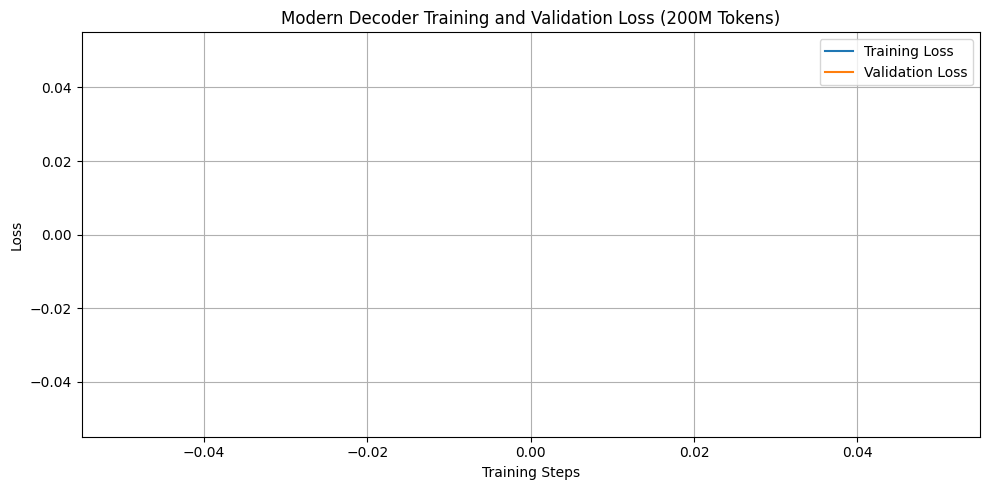

In [22]:
# ---------------------------------------------------------
# 6. Plotting Training and Validation Loss
# ---------------------------------------------------------
logs = trainer.state.log_history
train_steps, train_loss = [], []
eval_steps, eval_loss_history = [], []

for log in logs:
    if "loss" in log and "step" in log:
        train_steps.append(log["step"])
        train_loss.append(log["loss"])
    if "eval_loss" in log and "step" in log:
        eval_steps.append(log["step"])
        eval_loss_history.append(log["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss_history, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Modern Decoder Training and Validation Loss (200M Tokens)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
print(f"Loss plot saved to: {LOSS_PLOT_PATH}")

## 14. Save Final Model to Kaggle Output

In [24]:
trainer.save_model(MODEL_OUTPUT_DIR)
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
print(f"Final model saved to {MODEL_OUTPUT_DIR}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

KeyboardInterrupt: 

## 15. Push Model to Hugging Face Hub

In [ ]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [ ]:
test_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename="Phase_1_Pretraining/Test/test.json", repo_type="dataset", token=HF_TOKEN)

with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

predictions = {}
items = list(test_data.items())

for start in range(0, len(items), 32):
    batch = items[start:start + 32]
    batch_ids = [str(eid) for eid, _ in batch]
    batch_prompts = [record["text"] for _, record in batch]

    inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True, truncation=True, max_length=MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    input_lengths = inputs["attention_mask"].sum(dim=1)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_GENERATION_TOKENS,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            repetition_penalty=1.2,
            no_repeat_ngram_size=3
        )

    for i, example_id in enumerate(batch_ids):
        generated_tokens = outputs[i, input_lengths[i]:]
        generated_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)
        generated_words = generated_text.split()[:TARGET_GENERATION_WORDS]
        predictions[example_id] = {"text": " ".join(generated_words)}

# Save prediction.json
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

print("prediction.json saved successfully.")

# Create CodaBench Submission ZIP
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")
    
print(f"Codabench submission created at: {SUBMISSION_ZIP}")

## 17. Load Test Prompts

## 18. Load Final Model for Generation

## 19. Generate 128 Words
#### (words, not tokens)

## 20. Generate Predictions for the Test Set

## 21. Save prediction.json

In [ ]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

print("prediction.json saved:")
print(PREDICTION_PATH)

## 22. Create CodaBench Submission ZIP

In [ ]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")
print("Codabench submission created:")
print(SUBMISSION_ZIP)